# Hybrid 07 · Comparison of five model families (follow-up)

**Question:** can another model family, tuned the same way, grade better than the tuned Random Forest hybrid served by the application?

**Derived from:** `notebooks/images/14_model_family_comparison.ipynb`. **Status: planned follow-up.** Raised after notebook 13's results were known and run on the **same outer folds**, so it is **not independent confirmation**.
**Design:** as Hybrid 06 (25 outer folds on K3/K4, 3-fold donor-grouped inner tuning). Candidates: histogram gradient boosting, logistic regression, RBF SVM and Extra Trees, each as tabular and hybrid (8 arms). References: the ECD tree and notebook 13's tuned Random Forests, refitted from their per-fold selections.

**Runtime and reproduction:** the full run takes ≈42 min on 12 processes. By default the notebook re-runs the three references and three candidate arms (gradient boosting, logistic regression and SVM, tabular) on one outer fold (≈3 min), checks them against the saved results, then loads `model_family_fold_scores.csv` (written by notebook 14) and recomputes every comparison. `RUN_FULL_FAMILY_COMPARISON = True` recomputes all 25 folds in memory; nothing is written.

In [1]:
RUN_FULL_FAMILY_COMPARISON = False
CHECK_FOLD = (0, 0)
CHECK_CANDIDATES = ["Gradient boosting tabular", "Logistic regression tabular", "RBF SVM tabular"]

Set up paths (worker processes need the project modules on `PYTHONPATH`), the cohort and the feature matrix.

In [2]:
import json
import os
import sys
import time
import warnings
from pathlib import Path

GRADING_DIR = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "scripts" / "modeling_setup.py").is_file())
MODULE_DIRS = [str(GRADING_DIR / "scripts"), str(GRADING_DIR / "notebooks_cleaned")]
sys.path[:0] = MODULE_DIRS
os.environ["PYTHONPATH"] = os.pathsep.join(MODULE_DIRS + [os.environ.get("PYTHONPATH", "")])

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from joblib import Parallel, delayed
from sklearn.ensemble import ExtraTreesClassifier, HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from threadpoolctl import threadpool_limits

import cleaned_setup as cs
import modeling_setup as ms

warnings.filterwarnings("ignore", category=UserWarning)
k3, folds, has_ecd = cs.primary_cohort()
X, y, donors = cs.feature_matrix(k3)
P = ms.PROCESSED_DIR
for name in ["model_family_fold_scores.csv", "model_family_selections.csv", "nested_tuning_selections.csv"]:
    print(f"{name}: sha256 {cs.sha256(P / name)}…")

model_family_fold_scores.csv: sha256 9b737a4bd5191223…
model_family_selections.csv: sha256 7ae1e2cde4479a8e…
nested_tuning_selections.csv: sha256 7ff3077bc130fa81…


## 1. Candidate families and search spaces (fixed before the run; grid order = tie-break order)

Hybrid arms tune PCA {8, 16, 32}. Candidates standardise the PCA components as well (logistic regression and the SVM depend on feature scale; trees are unaffected).

In [3]:
GRIDS = {
    "HGB": [{"learning_rate": rate, "max_iter": it, "max_leaf_nodes": leaves, "min_samples_leaf": leaf,
             "l2_regularization": l2, "class_weight": w}
            for rate, it in [(0.03, 300), (0.1, 100)] for leaves in [7, 15] for leaf in [20, 10]
            for l2 in [1.0, 0.0] for w in ["balanced", None]],
    "LR": [{"C": c, "class_weight": w} for c in [0.001, 0.01, 0.1, 1, 10] for w in ["balanced", None]],
    "SVM": [{"C": c, "gamma": g, "class_weight": w} for c in [0.1, 1, 10, 100] for g in ["scale", 0.01, 0.001] for w in ["balanced", None]],
    "ET": [{"min_samples_leaf": leaf, "max_depth": d, "max_features": f, "class_weight": w}
           for leaf in [5, 2, 1] for d in [15, None] for f in ["sqrt", 0.3] for w in ["balanced", None]],
}
FAMILY_NAMES = {"HGB": "Gradient boosting", "LR": "Logistic regression", "SVM": "RBF SVM", "ET": "Extra Trees"}
ARMS = {"tabular": [None], "hybrid": [8, 16, 32]}
CANDIDATES = [f"{FAMILY_NAMES[f]} {a}" for f in GRIDS for a in ARMS]
REFERENCES = ["ECD tree", "Tuned RF tabular", "Tuned RF hybrid"]
MODELS = REFERENCES + CANDIDATES
pd.Series({FAMILY_NAMES[f]: len(g) for f, g in GRIDS.items()}, name="Settings per PCA option").to_frame()

,Settings per PCA option
Gradient boosting,32
Logistic regression,10
RBF SVM,24
Extra Trees,24


Model constructors and the inner tuning loop (code from notebook 14).

In [4]:
def make_model(family, setting):
    if family == "HGB":
        return HistGradientBoostingClassifier(early_stopping=False, random_state=cs.SEED, **setting)
    if family == "LR":
        return LogisticRegression(solver="lbfgs", max_iter=5000, **setting)
    if family == "SVM":
        return SVC(kernel="rbf", **setting)
    return ExtraTreesClassifier(n_estimators=300, random_state=cs.SEED, n_jobs=1, **setting)


def tune(rows, family, pca_options, X, y, donors):
    candidates = [(k, s) for k in pca_options for s in GRIDS[family]]
    scores = np.zeros((3, len(candidates)))
    for i, (tr, va) in enumerate(StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=cs.SEED)
                                 .split(rows, y[rows], groups=donors[rows])):
        tr, va = rows[tr], rows[va]
        assert set(y[va]) == set(cs.CLASSES) and set(donors[tr]).isdisjoint(donors[va])
        for k in pca_options:
            pre = cs.preprocessor(k, scale_components=True).fit(X.iloc[tr], y[tr])
            Z_tr, Z_va = pre.transform(X.iloc[tr]), pre.transform(X.iloc[va])
            for j, (kk, setting) in enumerate(candidates):
                if kk == k:
                    scores[i, j] = cs.macro_f1(y[va], make_model(family, setting).fit(Z_tr, y[tr]).predict(Z_va))
    mean = scores.mean(axis=0)
    return candidates[int(np.argmax(mean))], mean.max()


def run_candidates(repeat, fold, train, test, X, y, donors, has_ecd, names):
    """Tune and refit the named candidates for one outer fold, single-threaded as in notebook 14's workers."""
    with threadpool_limits(1), warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")
        eval_test = test[has_ecd[test]]
        predictions, selections = {}, []
        for family in GRIDS:
            for arm, pca_options in ARMS.items():
                name = f"{FAMILY_NAMES[family]} {arm}"
                if name not in names:
                    continue
                (k, setting), inner = tune(train, family, pca_options, X, y, donors)
                model = Pipeline([("features", cs.preprocessor(k, scale_components=True)), ("classifier", make_model(family, setting))])
                predictions[name] = model.fit(X.iloc[train], y[train]).predict(X.iloc[eval_test])
                selections.append({"Model": name, "Repeat": repeat, "Fold": fold, "PCA": k, "Setting": json.dumps(setting), "Inner macro F1": inner})
    return {"repeat": repeat, "fold": fold, "eval_test": eval_test, "predictions": predictions, "selections": selections,
            "convergence_warnings": sum(issubclass(w.category, ConvergenceWarning) for w in caught)}

References are refitted from notebook 13's per-fold selections in the main process with default threading, as in notebook 13 (PCA rounding depends on the BLAS thread count; notebook 14 deviations log).

In [5]:
nb13 = pd.read_csv(P / "nested_tuning_selections.csv", dtype={"max_features": str})
rf_settings = {
    ({"Tuned tabular": "Tuned RF tabular", "Tuned hybrid": "Tuned RF hybrid"}[r["Arm"]], int(r["Repeat"]), int(r["Fold"])): (
        None if pd.isna(r["PCA"]) else int(r["PCA"]),
        {"min_samples_leaf": int(r["min_samples_leaf"]), "max_depth": None if pd.isna(r["max_depth"]) else int(r["max_depth"]),
         "max_features": r["max_features"] if r["max_features"] == "sqrt" else float(r["max_features"]),
         "class_weight": None if pd.isna(r["class_weight"]) else r["class_weight"]})
    for r in nb13.to_dict("records")
}


def run_references(repeat, fold, train, test):
    eval_test, train_ecd = test[has_ecd[test]], train[has_ecd[train]]
    predictions = {"ECD tree": cs.ecd_tree().fit(X.iloc[train_ecd], y[train_ecd]).predict(X.iloc[eval_test])}
    for name in ["Tuned RF tabular", "Tuned RF hybrid"]:
        k, setting = rf_settings[(name, repeat, fold)]
        model = Pipeline([("features", cs.preprocessor(k)),
                          ("classifier", RandomForestClassifier(n_estimators=300, random_state=cs.SEED, n_jobs=1, **setting))])
        predictions[name] = model.fit(X.iloc[train], y[train]).predict(X.iloc[eval_test])
    return predictions

## 2. Run (all 25 folds in parallel, or the check fold) and verify against notebook 14

In [6]:
jobs = [(r, f, tr, te) for r in range(ms.N_REPEATS) for f, (tr, te) in enumerate(ms.iter_donor_folds(folds, k3["Tissue_ID"], r))]
N_TRAIN, N_TEST = np.mean([(len(tr), len(te)) for _, _, tr, te in jobs], axis=0)
run_jobs = jobs if RUN_FULL_FAMILY_COMPARISON else [j for j in jobs if j[:2] == CHECK_FOLD]
names = CANDIDATES if RUN_FULL_FAMILY_COMPARISON else CHECK_CANDIDATES

start = time.time()
outputs = Parallel(n_jobs=min(12, os.cpu_count(), len(run_jobs)), backend="loky")(
    delayed(run_candidates)(r, f, tr, te, X, y, donors, has_ecd, names) for r, f, tr, te in run_jobs)
rows, selection_rows = [], []
for out, (r, f, tr, te) in zip(outputs, run_jobs):
    out["predictions"] = {**run_references(r, f, tr, te), **out["predictions"]}
    selection_rows += out["selections"]
    rows += [{"Model": m, "Repeat": r, "Fold": f, "N": len(out["eval_test"]),
              **{k: fn(y[out["eval_test"]], p) for k, fn in cs.METRICS_WITH_KAPPA.items()}} for m, p in out["predictions"].items()]
live_scores, live_selections = pd.DataFrame(rows), pd.DataFrame(selection_rows)
print(f"{len(run_jobs)} outer fold(s) in {(time.time() - start) / 60:.1f} min; "
      f"logistic regression convergence warnings: {sum(o['convergence_warnings'] for o in outputs)}")

saved_scores = pd.read_csv(P / "model_family_fold_scores.csv")
saved_selections = pd.read_csv(P / "model_family_selections.csv")
key = ["Model", "Repeat", "Fold"]
a = live_scores.set_index(key)[list(cs.METRICS_WITH_KAPPA)].sort_index()
print(f"Live vs notebook 14: max absolute metric difference {(a - saved_scores.set_index(key).loc[a.index, list(cs.METRICS_WITH_KAPPA)]).abs().to_numpy().max():.1e}")
live_sel = live_selections.assign(PCA=live_selections["PCA"].map(lambda k: "none" if k is None else str(k))).set_index(key)
print("Selected settings equal notebook 14:", live_sel["Setting"].equals(saved_selections.set_index(key).loc[live_sel.index, "Setting"])
      and (live_sel["PCA"] == saved_selections.set_index(key).loc[live_sel.index, "PCA"].astype(str)).all())

fold_scores = live_scores if RUN_FULL_FAMILY_COMPARISON else saved_scores
print("Source of the 25-fold results:", "recomputed in this session" if RUN_FULL_FAMILY_COMPARISON else f"model_family_fold_scores.csv (verified on fold {CHECK_FOLD})")

1 outer fold(s) in 0.9 min; logistic regression convergence warnings: 0
Live vs notebook 14: max absolute metric difference 0.0e+00
Selected settings equal notebook 14: True
Source of the 25-fold results: model_family_fold_scores.csv (verified on fold (0, 0))


## 3. Results on the 470 K4 tissues (fold-level mean ± SD over 25 folds)

In [7]:
cs.summarise(fold_scores, MODELS, cs.METRICS_WITH_KAPPA)

,Macro F1,Balanced accuracy,Accuracy,Recall B,Kappa (quadratic)
ECD tree,0.796 ± 0.038,0.768 ± 0.043,0.804 ± 0.031,0.790 ± 0.117,0.771 ± 0.056
Tuned RF tabular,0.805 ± 0.034,0.781 ± 0.037,0.809 ± 0.030,0.793 ± 0.115,0.783 ± 0.043
Tuned RF hybrid,0.793 ± 0.047,0.775 ± 0.050,0.797 ± 0.040,0.789 ± 0.130,0.764 ± 0.066
Gradient boosting tabular,0.785 ± 0.046,0.770 ± 0.046,0.782 ± 0.038,0.806 ± 0.114,0.753 ± 0.048
Gradient boosting hybrid,0.792 ± 0.034,0.770 ± 0.039,0.788 ± 0.033,0.796 ± 0.123,0.764 ± 0.048
Logistic regression tabular,0.698 ± 0.058,0.686 ± 0.056,0.709 ± 0.053,0.690 ± 0.131,0.675 ± 0.065
Logistic regression hybrid,0.678 ± 0.063,0.677 ± 0.062,0.695 ± 0.055,0.713 ± 0.145,0.665 ± 0.071
RBF SVM tabular,0.715 ± 0.049,0.701 ± 0.047,0.731 ± 0.047,0.673 ± 0.134,0.699 ± 0.054
RBF SVM hybrid,0.681 ± 0.050,0.673 ± 0.054,0.699 ± 0.049,0.659 ± 0.147,0.664 ± 0.074
Extra Trees tabular,0.709 ± 0.046,0.701 ± 0.049,0.730 ± 0.039,0.692 ± 0.129,0.702 ± 0.043


Primary family P: each candidate − the deployed tuned RF hybrid (macro F1, Holm across 8). Secondary family S: each candidate − ECD tree (Holm across 8). Recomputed and checked against `model_family_results.csv`.

In [8]:
families = {}
for family, baseline in {"P": "Tuned RF hybrid", "S": "ECD tree"}.items():
    res = cs.paired_comparisons(fold_scores, {f"{family}{i}": (c, baseline) for i, c in enumerate(CANDIDATES, 1)},
                                cs.METRICS_WITH_KAPPA, N_TRAIN, N_TEST)
    res["Verdict"] = [cs.verdict(d, p) if m == "Macro F1" else "" for d, p, m in zip(res["Difference"], res["p (Holm)"], res["Metric"])]
    families[family] = res
saved_results = pd.read_csv(P / "model_family_results.csv")
both = pd.concat(families.values()).merge(saved_results, on=["ID", "Metric"], suffixes=("", " saved"))
print("Max difference from notebook 14's comparisons:",
      f"{max((both[c] - both[c + ' saved']).abs().max() for c in ['Difference', 'CI low', 'CI high', 'p']):.1e};",
      "verdicts equal:", (both.loc[both['Metric'] == 'Macro F1', 'Verdict'] == both.loc[both['Metric'] == 'Macro F1', 'Verdict saved']).all())
P_family = families["P"][families["P"]["Metric"] == "Macro F1"]
P_family[["ID", "Comparison", "Difference", "CI low", "CI high", "p (Holm)", "Folds improved", "Verdict"]].round(4)

Max difference from notebook 14's comparisons: 1.7e-16; verdicts equal: True


,ID,Comparison,Difference,CI low,CI high,p (Holm),Folds improved,Verdict
0,P1,Gradient boosting tabular − Tuned RF hybrid,-0.0085,-0.0462,0.0291,1.0000,9/25,Inconclusive
5,P2,Gradient boosting hybrid − Tuned RF hybrid,-0.0013,-0.0407,0.0381,1.0000,11/25,Inconclusive
10,P3,Logistic regression tabular − Tuned RF hybrid,-0.0953,-0.1588,-0.0318,0.0274,1/25,Worse
15,P4,Logistic regression hybrid − Tuned RF hybrid,-0.1150,-0.1873,-0.0427,0.0220,1/25,Worse
20,P5,RBF SVM tabular − Tuned RF hybrid,-0.0782,-0.1336,-0.0228,0.0274,1/25,Worse
25,P6,RBF SVM hybrid − Tuned RF hybrid,-0.1121,-0.1641,-0.0601,0.0013,0/25,Worse
30,P7,Extra Trees tabular − Tuned RF hybrid,-0.0841,-0.1403,-0.0279,0.0274,1/25,Worse
35,P8,Extra Trees hybrid − Tuned RF hybrid,-0.0689,-0.1143,-0.0234,0.0274,2/25,Worse


The primary family as a chart: gradient boosting is indistinguishable from the RF hybrid; the other families are clearly worse.

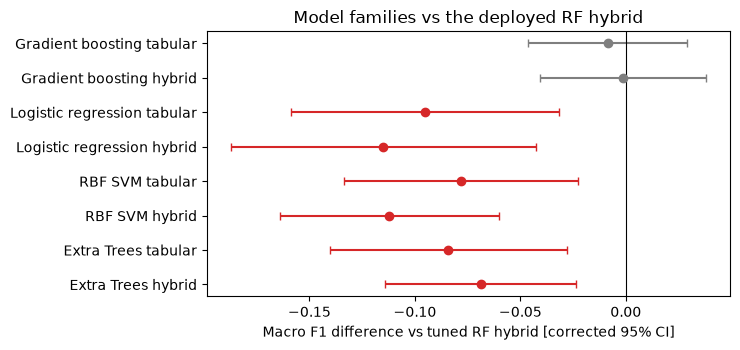

In [9]:
fig, ax = plt.subplots(figsize=(7.5, 3.6))
for i, (_, r) in enumerate(P_family.iterrows()):
    color = {"Worse": "tab:red", "Inconclusive": "tab:grey", "Improved": "tab:green"}[r["Verdict"]]
    ax.errorbar(r["Difference"], i, xerr=[[r["Difference"] - r["CI low"]], [r["CI high"] - r["Difference"]]], fmt="o", capsize=3, color=color)
ax.axvline(0, color="black", lw=0.8)
ax.set(yticks=range(len(P_family)), yticklabels=[c.replace(" − Tuned RF hybrid", "") for c in P_family["Comparison"]],
       xlabel="Macro F1 difference vs tuned RF hybrid [corrected 95% CI]", title="Model families vs the deployed RF hybrid")
ax.invert_yaxis()
plt.tight_layout()
plt.show()

Secondary family S (against the ECD tree): no candidate beats it.

In [10]:
S_family = families["S"][families["S"]["Metric"] == "Macro F1"]
S_family[["ID", "Comparison", "Difference", "CI low", "CI high", "p (Holm)", "Verdict"]].round(4)

,ID,Comparison,Difference,CI low,CI high,p (Holm),Verdict
0,S1,Gradient boosting tabular − ECD tree,-0.0110,-0.0393,0.0172,0.8562,Inconclusive
5,S2,Gradient boosting hybrid − ECD tree,-0.0037,-0.0321,0.0246,0.8562,Inconclusive
10,S3,Logistic regression tabular − ECD tree,-0.0978,-0.1626,-0.0329,0.0165,Worse
15,S4,Logistic regression hybrid − ECD tree,-0.1175,-0.1863,-0.0487,0.0105,Worse
20,S5,RBF SVM tabular − ECD tree,-0.0807,-0.1332,-0.0281,0.0165,Worse
25,S6,RBF SVM hybrid − ECD tree,-0.1146,-0.1706,-0.0586,0.0024,Worse
30,S7,Extra Trees tabular − ECD tree,-0.0866,-0.1401,-0.0331,0.0137,Worse
35,S8,Extra Trees hybrid − ECD tree,-0.0714,-0.1086,-0.0341,0.0042,Worse


Per-grade precision/recall and quadratic-weighted kappa (order B < A < A+), pooled over repeats from the saved out-of-fold predictions, checked against `model_family_per_grade.csv`.

In [11]:
oof = pd.read_csv(P / "model_family_oof_predictions.csv")
table = cs.per_grade(oof["Actual"], {m: oof[m] for m in MODELS}).T.unstack(level=1).reindex(MODELS)
table["Kappa (quadratic)"] = [cs.kappa(oof["Actual"], oof[m]) for m in MODELS]
saved_pg = pd.read_csv(P / "model_family_per_grade.csv", header=[0, 1], index_col=0)
cols = [(g, s) for g in cs.CLASSES for s in ["Precision", "Recall"]]
diff = max(np.abs(table[cols].to_numpy() - saved_pg.loc[MODELS, cols].to_numpy(dtype=float)).max(),
           np.abs(table["Kappa (quadratic)"].to_numpy().ravel() - saved_pg.loc[MODELS].iloc[:, -1].to_numpy(dtype=float)).max())
print(f"Max difference from notebook 14's per-grade and kappa table: {diff:.1e}")
table.round(3)

Max difference from notebook 14's per-grade and kappa table: 1.1e-16


A+                A                B  \
                            Precision Recall Precision Recall Precision   
ECD tree                        0.748  0.988     0.884  0.528     1.000   
Tuned RF tabular                0.779  0.943     0.805  0.609     0.978   
Tuned RF hybrid                 0.788  0.906     0.761  0.635     0.936   
Gradient boosting tabular       0.784  0.870     0.719  0.636     0.928   
Gradient boosting hybrid        0.777  0.892     0.733  0.625     0.982   
Logistic regression tabular     0.752  0.816     0.593  0.552     0.808   
Logistic regression hybrid      0.748  0.811     0.578  0.504     0.719   
RBF SVM tabular                 0.775  0.830     0.622  0.603     0.832   
RBF SVM hybrid                  0.759  0.803     0.577  0.558     0.761   
Extra Trees tabular             0.765  0.857     0.633  0.552     0.790   
Extra Trees hybrid              0.779  0.906     0.694  0.538     0.759   

                                   Kappa (quadratic)  
                            Recall                    
ECD tree                     0.791             0.772  
Tuned RF tabular             0.794             0.785  
Tuned RF hybrid              0.791             0.769  
Gradient boosting tabular    0.809             0.756  
Gradient boosting hybrid     0.797             0.767  
Logistic regression tabular  0.690             0.677  
Logistic regression hybrid   0.716             0.668  
RBF SVM tabular              0.678             0.702  
RBF SVM hybrid               0.657             0.667  
Extra Trees tabular          0.687             0.703  
Extra Trees hybrid           0.713             0.738

## 4. Application rule (fixed before the run)

A candidate would be recommended only if it convincingly outperforms the deployed model: macro F1 difference > 0, Holm p < 0.05 and grade B recall difference ≥ −0.02.

In [12]:
b_recall = families["P"][families["P"]["Metric"] == "Recall B"].set_index("ID")["Difference"]
convincing = [r["Comparison"] for _, r in P_family.iterrows() if r["Difference"] > 0 and r["p (Holm)"] < 0.05 and b_recall[r["ID"]] >= -0.02]
print("Candidates that convincingly outperform the tuned RF hybrid:", convincing or "none -> the deployed tuned RF hybrid is retained")

Candidates that convincingly outperform the tuned RF hybrid: none -> the deployed tuned RF hybrid is retained


## Interpretation (follow-up on reused folds)

- **Gradient boosting** reached the same level as the Random Forest (hybrid −0.001 [−0.041, +0.038], tabular −0.009; Holm p = 1.00): indistinguishable, not "as good" (no equivalence margin was set).
- **Logistic regression, the RBF SVM and Extra Trees** were worse than the RF hybrid by 0.07–0.12 macro F1 (Holm p ≤ 0.027) and also worse than the ECD tree.
- **No family beat the ECD tree**, so "improvement beyond ECD alone was not established" holds across five model families. The deployed tuned RF hybrid is retained under the pre-set rule.
- A possible (untested) explanation: the labels are anchored at two ECD cut points, which models with sharp, optimised thresholds (RF, boosting, the tree) fit well.

**Limitations:** raised after notebook 13 and evaluated on the same outer folds: not independent confirmation. Kappa measures agreement with one recorded grade per tissue, not inter-rater reliability.